## **Limpeza de dados**

### **Tratamento de missings (NA, NaN)**

In [1]:
import pandas as pd

| Coluna | Descrição |
|---|---|
| `lote_id` | Identificador do lote de produção |
| `data_producao` | Data da produção |
| `maquina` | Identificação da máquina |
| `turno` | Turno de trabalho |
| `pecas_produzidas` | Quantidade de peças produzidas |
| `pecas_defeituosas` | Quantidade de peças com defeito |
| `temperatura_c` | Temperatura do equipamento (°C) |
| `pressao_bar` | Pressão de operação (bar) |
| `tempo_ciclo_seg` | Tempo médio do ciclo produtivo (segundos) |
| `consumo_energia_kwh` | Energia consumida (kWh) |

In [2]:
df_industria = pd.read_excel("df_industria.xlsx")

df_industria

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1014,2026-09-03,NaN,Noite,386.0,2,85.2,7.58,72.5,137.46
1,1040,2026-09-08,M-03,Noite,349.0,58,90.2,7.97,74.8,96.69
2,1031,2026-09-07,M-02,Manhã,365.0,3,70.0,5.27,68.0,106.69
3,1046,2026-09-10,M-04,Noite,264.0,6,79.6,5.26,51.0,126.49
4,1018,2026-09-04,M-01,Noite,373.0,5,89.7,6.69,75.2,780.00
5,1020,2026-09-04,M-02,Manhã,385.0,5,NaN,6.64,52.0,129.07
6,1027,2026-09-06,M-02,Tarde,299.0,3,78.4,6.22,67.4,160.33
7,1026,2026-09-06,M-03,Manhã,282.0,3,85.3,23.50,62.2,154.68
8,1033,2026-09-07,M-01,Tarde,397.0,0,69.0,5.16,51.7,119.83
9,1020,2026-09-04,M-02,Manhã,385.0,5,NaN,6.64,52.0,129.07


In [3]:
df_industria.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   lote_id              50 non-null     int64         
 1   data_producao        50 non-null     datetime64[ns]
 2   maquina              49 non-null     object        
 3   turno                49 non-null     object        
 4   pecas_produzidas     49 non-null     float64       
 5   pecas_defeituosas    50 non-null     int64         
 6   temperatura_c        46 non-null     float64       
 7   pressao_bar          48 non-null     float64       
 8   tempo_ciclo_seg      50 non-null     float64       
 9   consumo_energia_kwh  49 non-null     float64       
dtypes: datetime64[ns](1), float64(5), int64(2), object(2)
memory usage: 4.0+ KB


In [4]:
# Identificando os valores ausentes
display(df_industria.isna())

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,False,False,True,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,True,False,False,False
6,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False
9,False,False,False,False,False,False,True,False,False,False


In [5]:
# Contando os valores ausentes por coluna
print(df_industria.isna().sum())

lote_id                0
data_producao          0
maquina                1
turno                  1
pecas_produzidas       1
pecas_defeituosas      0
temperatura_c          4
pressao_bar            2
tempo_ciclo_seg        0
consumo_energia_kwh    1
dtype: int64


In [6]:
# Quantidade total de valores ausentes
print("Total:", df_industria.isna().sum().sum())

Total: 10


In [7]:
# Substituindo valores ausentes por um valor fixo.
# A função fillna() permite preencher valores ausentes sem remover registros.

# Criando uma cópia para preservar os dados originais
df_tratado = df_industria.copy()

# Substituindo os valores ausentes
df_tratado["maquina"] = df_tratado["maquina"].fillna(
    "Não informada"
)

df_tratado["turno"] = df_tratado["turno"].fillna(
    "Não informado"
)

# Conferindo o resultado
print(df_tratado[["maquina", "turno"]].isna().sum())

df_tratado

maquina    0
turno      0
dtype: int64


,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1014,2026-09-03,Não informada,Noite,386.0,2,85.2,7.58,72.5,137.46
1,1040,2026-09-08,M-03,Noite,349.0,58,90.2,7.97,74.8,96.69
2,1031,2026-09-07,M-02,Manhã,365.0,3,70.0,5.27,68.0,106.69
3,1046,2026-09-10,M-04,Noite,264.0,6,79.6,5.26,51.0,126.49
4,1018,2026-09-04,M-01,Noite,373.0,5,89.7,6.69,75.2,780.00
5,1020,2026-09-04,M-02,Manhã,385.0,5,NaN,6.64,52.0,129.07
6,1027,2026-09-06,M-02,Tarde,299.0,3,78.4,6.22,67.4,160.33
7,1026,2026-09-06,M-03,Manhã,282.0,3,85.3,23.50,62.2,154.68
8,1033,2026-09-07,M-01,Tarde,397.0,0,69.0,5.16,51.7,119.83
9,1020,2026-09-04,M-02,Manhã,385.0,5,NaN,6.64,52.0,129.07


In [8]:
# Substituindo valores ausentes pela média


# Calculando a temperatura média
media_temperatura = df_tratado["temperatura_c"].mean()

print("Temperatura média:", media_temperatura)

# Substituindo os valores ausentes pela média
df_tratado["temperatura_c"] = (
    df_tratado["temperatura_c"].fillna(media_temperatura)
)

# Verificando o resultado
print(df_tratado["temperatura_c"].isna().sum())

df_tratado

Temperatura média: 82.98260869565216
0


,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1014,2026-09-03,Não informada,Noite,386.0,2,85.200000,7.58,72.5,137.46
1,1040,2026-09-08,M-03,Noite,349.0,58,90.200000,7.97,74.8,96.69
2,1031,2026-09-07,M-02,Manhã,365.0,3,70.000000,5.27,68.0,106.69
3,1046,2026-09-10,M-04,Noite,264.0,6,79.600000,5.26,51.0,126.49
4,1018,2026-09-04,M-01,Noite,373.0,5,89.700000,6.69,75.2,780.00
5,1020,2026-09-04,M-02,Manhã,385.0,5,82.982609,6.64,52.0,129.07
6,1027,2026-09-06,M-02,Tarde,299.0,3,78.400000,6.22,67.4,160.33
7,1026,2026-09-06,M-03,Manhã,282.0,3,85.300000,23.50,62.2,154.68
8,1033,2026-09-07,M-01,Tarde,397.0,0,69.000000,5.16,51.7,119.83
9,1020,2026-09-04,M-02,Manhã,385.0,5,82.982609,6.64,52.0,129.07


In [9]:
# Removendo linhas que possuem qualquer valor ausente
df_sem_missing = df_industria.dropna()

print("Antes:", df_industria.shape)
print("Depois:", df_sem_missing.shape)

df_sem_missing

Antes: (50, 10)
Depois: (40, 10)


,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
1,1040,2026-09-08,M-03,Noite,349.0,58,90.2,7.97,74.8,96.69
2,1031,2026-09-07,M-02,Manhã,365.0,3,70.0,5.27,68.0,106.69
3,1046,2026-09-10,M-04,Noite,264.0,6,79.6,5.26,51.0,126.49
4,1018,2026-09-04,M-01,Noite,373.0,5,89.7,6.69,75.2,780.00
6,1027,2026-09-06,M-02,Tarde,299.0,3,78.4,6.22,67.4,160.33
7,1026,2026-09-06,M-03,Manhã,282.0,3,85.3,23.50,62.2,154.68
8,1033,2026-09-07,M-01,Tarde,397.0,0,69.0,5.16,51.7,119.83
10,1013,2026-09-03,M-03,Noite,388.0,7,86.7,7.31,64.8,113.61
11,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
12,1038,2026-09-08,M-04,Noite,362.0,4,82.1,4.18,61.7,107.29


In [10]:
# Removendo apenas registros sem temperatura (considerando apenas uma coluna)
df_sem_temperatura_nula = df_industria.dropna(
    subset=["temperatura_c"]
)

print(df_sem_temperatura_nula.shape)

df_sem_temperatura_nula

(46, 10)


,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1014,2026-09-03,NaN,Noite,386.0,2,85.2,7.58,72.5,137.46
1,1040,2026-09-08,M-03,Noite,349.0,58,90.2,7.97,74.8,96.69
2,1031,2026-09-07,M-02,Manhã,365.0,3,70.0,5.27,68.0,106.69
3,1046,2026-09-10,M-04,Noite,264.0,6,79.6,5.26,51.0,126.49
4,1018,2026-09-04,M-01,Noite,373.0,5,89.7,6.69,75.2,780.00
6,1027,2026-09-06,M-02,Tarde,299.0,3,78.4,6.22,67.4,160.33
7,1026,2026-09-06,M-03,Manhã,282.0,3,85.3,23.50,62.2,154.68
8,1033,2026-09-07,M-01,Tarde,397.0,0,69.0,5.16,51.7,119.83
10,1013,2026-09-03,M-03,Noite,388.0,7,86.7,7.31,64.8,113.61
11,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64


In [11]:
# um pouco mais avançado

# considerar as três linhas imediatamente anteriores e calcular a média.

# Ordena o DataFrame pela data de produção e pelo identificador do lote
df_pressao = df_industria.sort_values(
    ["data_producao", "lote_id"]

# Reorganiza os índices, iniciando em 0, sem preservar o índice antigo
).reset_index(drop=True).copy()  # Cria uma cópia para preservar o DataFrame original

display(df_pressao)

# Calcula a média móvel dos três registros anteriores
media_movel = (

    df_pressao["pressao_bar"]  # Seleciona a coluna de pressão

    .shift(1)  # Desloca os valores uma linha para baixo, excluindo o valor atual do cálculo

    .rolling(
        window=3,       # Define uma janela móvel de três registros
        min_periods=3   # Exige três valores válidos para calcular a média
    )

    .mean()  # Calcula a média dos valores presentes em cada janela
)


# Substitui os valores ausentes pelas médias móveis calculadas
df_pressao["pressao_bar"] = (

    df_pressao["pressao_bar"]  # Seleciona a coluna original de pressão

    .fillna(media_movel)  # Preenche apenas os valores ausentes com a média correspondente
)

print(media_movel)

print(50*"-")

df_pressao

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1001,2026-09-01,M-01,Tarde,395.0,3,78.7,7.13,69.6,106.23
1,1002,2026-09-01,M-04,Noite,322.0,3,77.1,4.33,66.5,128.53
2,1003,2026-09-01,M-03,Noite,404.0,8,75.2,5.95,58.5,172.30
3,1004,2026-09-01,M-02,Noite,306.0,1,NaN,5.96,50.6,142.68
4,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
5,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
6,1006,2026-09-02,M-04,Manhã,369.0,3,70.1,6.29,55.3,159.35
7,1007,2026-09-02,M-01,Tarde,362.0,8,210.0,5.89,74.2,132.39
8,1008,2026-09-02,M-03,Tarde,282.0,7,91.1,5.07,54.7,157.78
9,1009,2026-09-02,M-01,Tarde,394.0,0,89.8,NaN,51.4,96.43


0           NaN
1           NaN
2           NaN
3      5.803333
4      5.413333
5      6.553333
6      7.153333
7      7.263333
8      6.643333
9      5.750000
10          NaN
11          NaN
12          NaN
13     5.310000
14     4.646667
15     5.163333
16     6.326667
17     6.483333
18     6.120000
19     5.070000
20     5.780000
21     5.413333
22     6.150000
23     6.133333
24     6.730000
25     6.873333
26     6.136667
27     6.386667
28     5.670000
29    12.026667
30    11.546667
31          NaN
32          NaN
33          NaN
34     6.606667
35     6.770000
36     6.080000
37     6.343333
38     5.413333
39     6.273333
40     5.806667
41     5.526667
42     4.340000
43     4.700000
44     5.963333
45     7.093333
46     7.510000
47     7.373333
48     7.373333
49     7.070000
Name: pressao_bar, dtype: float64
--------------------------------------------------


,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1001,2026-09-01,M-01,Tarde,395.0,3,78.7,7.130000,69.6,106.23
1,1002,2026-09-01,M-04,Noite,322.0,3,77.1,4.330000,66.5,128.53
2,1003,2026-09-01,M-03,Noite,404.0,8,75.2,5.950000,58.5,172.30
3,1004,2026-09-01,M-02,Noite,306.0,1,NaN,5.960000,50.6,142.68
4,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.750000,68.9,169.64
5,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.750000,68.9,169.64
6,1006,2026-09-02,M-04,Manhã,369.0,3,70.1,6.290000,55.3,159.35
7,1007,2026-09-02,M-01,Tarde,362.0,8,210.0,5.890000,74.2,132.39
8,1008,2026-09-02,M-03,Tarde,282.0,7,91.1,5.070000,54.7,157.78
9,1009,2026-09-02,M-01,Tarde,394.0,0,89.8,5.750000,51.4,96.43


In [37]:
# isna() — Filtrar registros com valores ausentes

# Filtrando os registros com temperatura ausente
df_temperatura_nula = df_industria[df_industria["temperatura_c"].isna()]

display(df_temperatura_nula)

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
14,1004,2026-09-01,M-02,Noite,306.0,1,NaN,5.96,50.6,142.68
5,1020,2026-09-04,M-02,Manhã,385.0,5,NaN,6.64,52.0,129.07
9,1020,2026-09-04,M-02,Manhã,385.0,5,NaN,6.64,52.0,129.07
37,1036,2026-09-08,M-01,Tarde,383.0,6,NaN,7.74,59.1,108.24


In [39]:
# notna() — Filtrar registros com valores presentes

# Filtrando os registros com temperatura preenchida
df_temperatura_valida = df_industria[df_industria["temperatura_c"].notna()]

display(df_temperatura_valida)

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
25,1001,2026-09-01,M-01,Tarde,395.0,3,78.7,7.13,69.6,106.23
33,1002,2026-09-01,M-04,Noite,322.0,3,77.1,4.33,66.5,128.53
35,1003,2026-09-01,M-03,Noite,404.0,8,75.2,5.95,58.5,172.30
17,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
11,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
29,1006,2026-09-02,M-04,Manhã,369.0,3,70.1,6.29,55.3,159.35
15,1007,2026-09-02,M-01,Tarde,362.0,8,210.0,5.89,74.2,132.39
45,1008,2026-09-02,M-03,Tarde,282.0,7,91.1,5.07,54.7,157.78
13,1009,2026-09-02,M-01,Tarde,394.0,0,89.8,NaN,51.4,96.43
20,1010,2026-09-02,M-01,Manhã,292.0,2,84.8,6.08,71.3,103.73


##### Resumo das principais funções

| Função | Finalidade |
|---|---|
| `isna()` | Identifica valores ausentes |
| `isnull()` | Equivalente a `isna()` |
| `notna()` | Identifica valores presentes |
| `sum()` | Permite contar ausências após aplicar `isna()` |
| `info()` | Apresenta tipos de dados e quantidades de valores não nulos |

### Remoção de duplicatas

In [12]:
df_industria = df_industria.sort_values(by = "lote_id")

df_industria

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
25,1001,2026-09-01,M-01,Tarde,395.0,3,78.7,7.13,69.6,106.23
33,1002,2026-09-01,M-04,Noite,322.0,3,77.1,4.33,66.5,128.53
35,1003,2026-09-01,M-03,Noite,404.0,8,75.2,5.95,58.5,172.30
14,1004,2026-09-01,M-02,Noite,306.0,1,NaN,5.96,50.6,142.68
17,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
11,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
29,1006,2026-09-02,M-04,Manhã,369.0,3,70.1,6.29,55.3,159.35
15,1007,2026-09-02,M-01,Tarde,362.0,8,210.0,5.89,74.2,132.39
45,1008,2026-09-02,M-03,Tarde,282.0,7,91.1,5.07,54.7,157.78
13,1009,2026-09-02,M-01,Tarde,394.0,0,89.8,NaN,51.4,96.43


In [13]:
# Identificando registros duplicados
df_industria.duplicated()

25    False
33    False
35    False
14    False
17    False
11     True
29    False
15    False
45    False
13    False
20    False
40    False
31    False
18     True
10    False
0     False
47    False
19    False
21    False
4     False
42    False
5     False
9      True
44    False
34    False
41    False
38    False
22    False
7     False
6     False
27    False
48    False
30    False
2     False
24    False
8     False
28    False
23    False
37    False
32    False
12    False
43     True
49    False
1     False
39    False
16    False
46    False
36    False
26    False
3     False
dtype: bool

In [14]:
# Contando quantos registros são duplicados
quantidade_duplicatas = df_industria.duplicated().sum()

print("Registros duplicados:", quantidade_duplicatas)

Registros duplicados: 4


In [16]:
# Identificando duplicatas pela coluna lote_id
duplicatas_lotes = df_industria.duplicated(
    subset=["lote_id"]
)

print("Lotes duplicados:", duplicatas_lotes.sum())

# Visualizando os registros
display(df_industria[duplicatas_lotes])

Lotes duplicados: 4


,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
11,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
18,1012,2026-09-03,M-04,Manhã,261.0,0,91.3,4.09,53.0,158.75
9,1020,2026-09-04,M-02,Manhã,385.0,5,NaN,6.64,52.0,129.07
43,1038,2026-09-08,M-04,Noite,362.0,4,82.1,4.18,61.7,107.29


In [ ]:
# Verificando combinações repetidas de máquina, data e turno
duplicatas_combinadas = df_industria.duplicated(
    subset=["maquina", "data_producao", "turno"]
)

print("Combinações repetidas:", duplicatas_combinadas.sum())

Combinações repetidas: 8


In [21]:
duplicatas_combinadas = df_industria[df_industria.duplicated(
    subset=["maquina", "data_producao", "turno"]
)]

duplicatas_combinadas[["maquina", "data_producao", "turno"]]

,maquina,data_producao,turno
17,M-02,2026-09-01,Noite
11,M-02,2026-09-01,Noite
13,M-01,2026-09-02,Tarde
18,M-04,2026-09-03,Manhã
47,M-03,2026-09-03,Noite
9,M-02,2026-09-04,Manhã
30,M-02,2026-09-06,Tarde
43,M-04,2026-09-08,Noite


In [ ]:
# Removendo registros duplicados com drop_duplicates()

# Criando uma cópia do DataFrame original
df_sem_duplicatas = df_industria.copy()

# Removendo registros completamente duplicados
df_sem_duplicatas = df_sem_duplicatas.drop_duplicates()

# Reorganizando os índices
df_sem_duplicatas = df_sem_duplicatas.reset_index(drop=True)

# Comparando as dimensões
print("Antes:", df_industria.shape)
print("Depois:", df_sem_duplicatas.shape)

Antes: (50, 10)
Depois: (46, 10)


In [23]:
display(df_sem_duplicatas)

,lote_id,data_producao,maquina,turno,pecas_produzidas,pecas_defeituosas,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh
0,1001,2026-09-01,M-01,Tarde,395.0,3,78.7,7.13,69.6,106.23
1,1002,2026-09-01,M-04,Noite,322.0,3,77.1,4.33,66.5,128.53
2,1003,2026-09-01,M-03,Noite,404.0,8,75.2,5.95,58.5,172.30
3,1004,2026-09-01,M-02,Noite,306.0,1,NaN,5.96,50.6,142.68
4,1005,2026-09-01,M-02,Noite,298.0,2,76.7,7.75,68.9,169.64
5,1006,2026-09-02,M-04,Manhã,369.0,3,70.1,6.29,55.3,159.35
6,1007,2026-09-02,M-01,Tarde,362.0,8,210.0,5.89,74.2,132.39
7,1008,2026-09-02,M-03,Tarde,282.0,7,91.1,5.07,54.7,157.78
8,1009,2026-09-02,M-01,Tarde,394.0,0,89.8,NaN,51.4,96.43
9,1010,2026-09-02,M-01,Manhã,292.0,2,84.8,6.08,71.3,103.73


In [ ]:
# Comparando os parâmetros keep
# Podemos definir quais registros serão preservados após a remoção.

# Mantendo a primeira ocorrência
df_primeiro = df_industria.drop_duplicates(subset=["lote_id"], keep="first")

# Mantendo a última ocorrência
df_ultimo = df_industria.drop_duplicates(subset=["lote_id"], keep="last")

# Removendo todas as ocorrências dos lotes duplicados
df_todos = df_industria.drop_duplicates(subset=["lote_id"], keep=False) # não recomendado!!!!!!!

print("keep='first':", len(df_primeiro))
print("keep='last':", len(df_ultimo))
print("keep=False:", len(df_todos))

keep='first': 46
keep='last': 46
keep=False: 42


##### Investigando duplicatas com informações conflitantes

##### Validando o impacto da remoção nos indicadores industriais

In [ ]:
# Total de peças antes da remoção
producao_antes = df_industria["pecas_produzidas"].sum()

# Total de peças após a remoção
producao_depois = df_sem_duplicatas["pecas_produzidas"].sum()

# Calculando a diferença
diferenca = producao_antes - producao_depois

# Calculando o percentual de superestimação
percentual = (diferenca / producao_depois) * 100

print(f"Produção antes: {producao_antes:.0f} peças")
print(f"Produção depois: {producao_depois:.0f} peças")
print(f"Diferença: {diferenca:.0f} peças")
print(f"Superestimação: {percentual:.2f}%")

Produção antes: 16690 peças
Produção depois: 15384 peças
Diferença: 1306 peças
Superestimação: 8.49%


##### A análise permite identificar quanto a produção registrada estava artificialmente elevada pela presença de duplicatas.

###### *** #######

Imagine agora que o mesmo lote industrial apareça duas vezes, mas com valores diferentes de pressão.

Nesse caso, temos um identificador repetido, mas não uma duplicata exata.

Vamos simular esse problema utilizando nossa base.

In [34]:
# um pouco mais avançado
# Investigando duplicatas com informações conflitantes

# Criando uma cópia para simular uma inconsistência
df_conflito = df_industria.copy()

# Localizando os registros do lote 1005
indices = df_conflito.index[df_conflito["lote_id"] == 1005]

# Alterando a pressão em uma das ocorrências
df_conflito.loc[indices[-1], "pressao_bar"] += 1.5

# Comparando as informações do lote
print(
    df_conflito.loc[
        df_conflito["lote_id"] == 1005,
        ["lote_id", "maquina", "pressao_bar"]
    ]
)

print(32*"*")

# Comparando os critérios de duplicação
print(
    "Duplicatas exatas:",
    df_conflito.duplicated().sum()
)

print(
    "Duplicatas por lote:",
    df_conflito.duplicated(subset=["lote_id"]).sum()
)

    lote_id maquina  pressao_bar
17     1005    M-02         7.75
11     1005    M-02         9.25
********************************
Duplicatas exatas: 3
Duplicatas por lote: 4


O que aconteceu?

Ao modificar uma das pressões do lote 1005, deixamos de ter duas linhas completamente idênticas.

Entretanto, o identificador continua repetido.

Esse tipo de situação exige uma decisão fundamentada: qual pressão representa a medição correta?

Sem informações complementares, não é possível determinar automaticamente.

No ambiente profissional, poderíamos verificar o histórico do sensor,

a data e hora da medição ou o registro de atualização para decidir qual ocorrência deve ser preservada.

In [42]:
# value_counts() — Contar a frequência dos registros

# Contando a frequência de cada lote
frequencia = df_industria["lote_id"].value_counts()

# Exibindo apenas os lotes que aparecem mais de uma vez
print(frequencia[frequencia > 1])

lote_id
1005    2
1012    2
1038    2
1020    2
Name: count, dtype: int64


#### Resumo dos comandos utilizados

| Operação | Código |
|----------|--------|
| Identificar duplicatas | `df.duplicated()` |
| Contar duplicatas | `df.duplicated().sum()` |
| Mostrar todas as ocorrências | `df[df.duplicated(keep=False)]` |
| Comparar colunas específicas | `df.duplicated(subset=["coluna"])` |
| Remover duplicatas | `df.drop_duplicates()` |
| Manter a primeira | `df.drop_duplicates(keep="first")` |
| Manter a última | `df.drop_duplicates(keep="last")` |
| Excluir todas as ocorrências repetidas | `df.drop_duplicates(keep=False)` |
| Contar a frequência de valores | `df["coluna"].value_counts()` |

### **Detecção e tratamento de outliers**

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [48]:
# Preparando o DataFrame para a análise

# Criando uma cópia e removendo registros duplicados
df_analise = df_industria.drop_duplicates().copy()

# Reorganizando o índice
df_analise = df_analise.reset_index(drop=True)

# Selecionando as variáveis numéricas que serão investigadas
colunas = [
    "temperatura_c",
    "pressao_bar",
    "tempo_ciclo_seg",
    "consumo_energia_kwh",
    "pecas_defeituosas"
]

# Conferindo as dimensões
print("Base original:", df_industria.shape)
print("Base para análise:", df_analise.shape)

Base original: (50, 10)
Base para análise: (46, 10)


In [ ]:
# Investigando os valores extremos
# O método describe() retorna informações como média, desvio-padrão, quartis, mínimo e máximo.

# Resumo estatístico das variáveis numéricas
estatisticas = df_analise[colunas].describe()

# Transpondo para facilitar a leitura
display(estatisticas.T.round(2))

,count,mean,std,min,25%,50%,75%,max
temperatura_c,43.0,82.96,20.93,68.50,75.25,79.60,85.25,210.0
pressao_bar,44.0,6.56,2.86,4.09,5.15,6.15,7.31,23.5
tempo_ciclo_seg,46.0,66.55,39.08,48.40,53.12,61.85,68.53,320.0
consumo_energia_kwh,45.0,144.89,99.71,96.43,107.29,129.07,154.68,780.0
pecas_defeituosas,46.0,5.22,8.37,0.00,2.00,4.00,6.75,58.0


In [54]:
# Selecionando as cinco maiores temperaturas
maiores_temperaturas = df_analise.sort_values(by = "temperatura_c", ascending= False).head(5)
# Visualizando os lotes e suas temperaturas
display(maiores_temperaturas[["lote_id", "maquina", "temperatura_c"]])

,lote_id,maquina,temperatura_c
14,1007,M-01,210.0
16,1012,M-04,91.3
41,1008,M-03,91.1
24,1045,M-01,91.0
1,1040,M-03,90.2


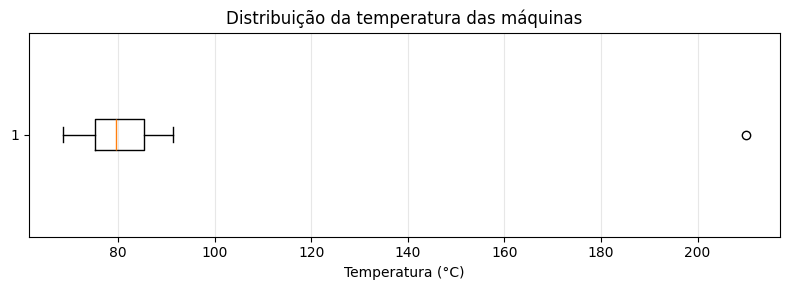

In [60]:
# Visualizando os dados com Boxplot


# Criando um gráfico para visualizar a temperatura
plt.figure(figsize=(8, 3))

# Construindo o Boxplot horizontal
plt.boxplot(df_analise["temperatura_c"].dropna(), orientation="horizontal")

# Configurando título e identificação do eixo
plt.title("Distribuição da temperatura das máquinas")
plt.xlabel("Temperatura (°C)")

# Adicionando uma grade discreta
plt.grid(axis="x", alpha=0.3)

# Ajustando a apresentação
plt.tight_layout()
plt.show()

O Boxplot (diagrama de caixa) é um gráfico estatístico que representa a distribuição de dados por meio dos quartis, da mediana e de limites de dispersão.

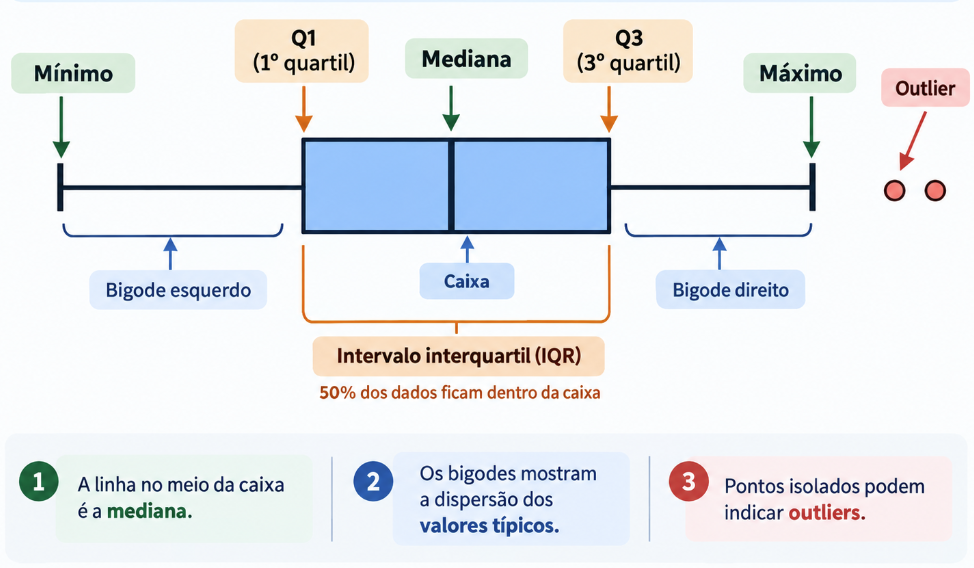

##### Identificando outliers com IQR: Amplitude Interquartil

O IQR (Interquartile Range) é uma medida estatística de dispersão calculada pela diferença entre o terceiro e o primeiro quartil.

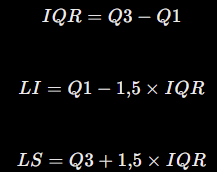

In [61]:
# Selecionando a coluna de temperatura
temperaturas = df_analise["temperatura_c"]

# Calculando o primeiro quartil (25%)
Q1 = temperaturas.quantile(0.25)

# Calculando o terceiro quartil (75%)
Q3 = temperaturas.quantile(0.75)

# Calculando o intervalo interquartil
IQR = Q3 - Q1

# Calculando os limites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Exibindo os resultados
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")


Q1: 75.25
Q3: 85.25
IQR: 10.00
Limite inferior: 60.25
Limite superior: 100.25


In [64]:
# Filtrando os registros identificados

# Criando uma condição para identificar os outliers
mascara_iqr = ((df_analise["temperatura_c"] < limite_inferior) | (df_analise["temperatura_c"] > limite_superior))

mascara_iqr

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14     True
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
32    False
33    False
34    False
35    False
36    False
37    False
38    False
39    False
40    False
41    False
42    False
43    False
44    False
45    False
Name: temperatura_c, dtype: bool

In [67]:
# Selecionando os registros atípicos
outliers_temperatura = df_analise.loc[mascara_iqr, ["lote_id", "maquina", "temperatura_c"]]

display(outliers_temperatura)

,lote_id,maquina,temperatura_c
14,1007,M-01,210.0


In [74]:
# DataFrame para armazenar os resultados booleanos
outliers_iqr = pd.DataFrame(index=df_analise.index)

# Percorrendo as cinco variáveis
for coluna in colunas:

    # Calculando os quartis
    Q1 = df_analise[coluna].quantile(0.25)
    Q3 = df_analise[coluna].quantile(0.75)

    # Calculando o IQR
    IQR = Q3 - Q1

    # Calculando os limites
    LI = Q1 - 1.5 * IQR
    LS = Q3 + 1.5 * IQR

    # Identificando os valores fora dos limites
    outliers_iqr[coluna] = ((df_analise[coluna] < LI) | (df_analise[coluna] > LS))


display(outliers_iqr)

print(85*"*")

# Contando os outliers por coluna
display(outliers_iqr.sum())

,temperatura_c,pressao_bar,tempo_ciclo_seg,consumo_energia_kwh,pecas_defeituosas
0,False,False,False,False,False
1,False,False,False,False,True
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,True,False
5,False,False,False,False,False
6,False,False,False,False,False
7,False,True,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False


*************************************************************************************


temperatura_c          1
pressao_bar            1
tempo_ciclo_seg        1
consumo_energia_kwh    1
pecas_defeituosas      1
dtype: int64

##### Tratamento de outliers por remoção

In [ ]:
# Identificando linhas com pelo menos um outlier
linhas_outliers = outliers_iqr.any(axis=1) # O método any(axis=1) verifica se existe pelo menos um outlier em cada linha.

# Criando um novo DataFrame sem essas linhas
df_sem_outliers = df_analise.loc[~linhas_outliers].copy() # O operador ~ representa a negação lógica (NOT).

# Reorganizando os índices
df_sem_outliers.reset_index(drop=True, inplace=True)

# Comparando as dimensões
print("Antes:", df_analise.shape)
print("Depois:", df_sem_outliers.shape)

Antes: (46, 10)
Depois: (41, 10)


In [78]:
# Avaliando o impacto da remoção


# Calculando as médias antes da remoção
media_antes = df_analise[colunas].mean()

# Calculando as médias depois da remoção
media_depois = df_sem_outliers[colunas].mean()

# Organizando os resultados
comparacao_medias = pd.DataFrame({"Antes": media_antes,"Depois": media_depois})

# Exibindo o resultado
display(comparacao_medias.round(2))

,Antes,Depois
temperatura_c,82.96,79.37
pressao_bar,6.56,6.15
tempo_ciclo_seg,66.55,59.87
consumo_energia_kwh,144.89,129.69
pecas_defeituosas,5.22,3.90


#### Em dados reais, a remoção precisaria ser justificada por uma investigação.

#### Resumo dos comandos utilizados

| Operação | Código |
|----------|--------|
| Resumo estatístico | `df.describe()` |
| Maiores valores | `df.nlargest(5, "coluna")` |
| Primeiro quartil | `serie.quantile(0.25)` |
| Terceiro quartil | `serie.quantile(0.75)` |
| Média | `serie.mean()` |
| Desvio-padrão | `serie.std(ddof=0)` |
| Identificar linhas com outliers | `mascara.any(axis=1)` |
| Inverter condição booleana | `~mascara` |
| Selecionar registros | `df.loc[condicao]` |

### **Normalização de dados**

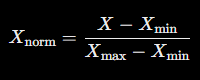

In [79]:
# Criando uma cópia do DataFrame
df_escala = df_industria.copy()

# Identificando a menor e a maior pressão
minimo = df_escala["pressao_bar"].min()
maximo = df_escala["pressao_bar"].max()

# Aplicando a normalização Min-Max
df_escala["pressao_normalizada"] = (df_escala["pressao_bar"] - minimo) / (maximo - minimo)

# Comparando os valores
display(df_escala[["pressao_bar", "pressao_normalizada"]].head(10))

,pressao_bar,pressao_normalizada
0,7.58,0.179804
1,7.97,0.199897
2,5.27,0.060793
3,5.26,0.060278
4,6.69,0.133952
5,6.64,0.131376
6,6.22,0.109737
7,23.50,1.000000
8,5.16,0.055126
9,6.64,0.131376


O que aconteceu?

- A menor pressão recebeu o valor 0.

- A maior pressão recebeu o valor 1.

- As demais pressões foram transformadas proporcionalmente para valores entre 0 e 1.

In [82]:
# Normalizando várias colunas simultaneamente

# Selecionando as colunas
colunas = [
    "temperatura_c",
    "pressao_bar",
    "consumo_energia_kwh"
]

# Criando uma cópia com as colunas selecionadas
df_normalizado = df_industria[colunas].copy()

# Percorrendo cada coluna
for coluna in colunas:

    # Identificando o menor e o maior valor
    minimo = df_normalizado[coluna].min()
    maximo = df_normalizado[coluna].max()

    # Aplicando a normalização Min-Max
    df_normalizado[f'{coluna}_norm'] = ((df_normalizado[coluna] - minimo) / (maximo - minimo))

# Visualizando o resultado
display(df_normalizado.head(10).round(2))

,temperatura_c,pressao_bar,consumo_energia_kwh,temperatura_c_norm,pressao_bar_norm,consumo_energia_kwh_norm
0,85.2,7.58,137.46,0.12,0.18,0.06
1,90.2,7.97,96.69,0.15,0.20,0.00
2,70.0,5.27,106.69,0.01,0.06,0.02
3,79.6,5.26,126.49,0.08,0.06,0.04
4,89.7,6.69,780.00,0.15,0.13,1.00
5,NaN,6.64,129.07,NaN,0.13,0.05
6,78.4,6.22,160.33,0.07,0.11,0.09
7,85.3,23.50,154.68,0.12,1.00,0.09
8,69.0,5.16,119.83,0.00,0.06,0.03
9,NaN,6.64,129.07,NaN,0.13,0.05


Nossa base industrial ainda possui alguns valores ausentes e extremos.

- Valores ausentes: permanecerão como NaN após as transformações.

- Outliers: podem influenciar a normalização e a padronização.

- Duplicatas: também podem afetar os parâmetros estatísticos calculados.